# Setup

In [1]:
# Setup for Kaggle
!git clone https://github.com/fastai/course22p2.git
!pip install -q fastcore einops datasets timm k-diffusion torcheval

import sys
sys.path.append('/kaggle/working/course22p2') 

import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'

import shutil, timm, os, torch, random, datasets, math
import fastcore.all as fc, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import k_diffusion as K, torchvision.transforms as T
import torchvision.transforms.functional as TF, torch.nn.functional as F
from torch.utils.data import DataLoader, default_collate
from pathlib import Path
from torch.nn import init
from fastcore.foundation import L
from torch import nn, tensor
from operator import itemgetter
from torcheval.metrics import MulticlassAccuracy
from functools import partial
from torch.optim import lr_scheduler
from torch import optim
from torchvision.io import read_image, ImageReadMode
from glob import glob
from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *
from miniai.training import *  
from fastprogress import progress_bar

torch.set_printoptions(precision=5, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['figure.dpi'] = 70
set_seed(42)
if fc.defaults.cpus > 8: fc.defaults.cpus = 8

torch.cuda.is_available()

fatal: destination path 'course22p2' already exists and is not an empty directory.


True

# Get Data ready

In [2]:
path_data = Path('../Data')
path_data.mkdir(exist_ok=True)
path = path_data/'tiny-imagenet-200'

url = 'http://cs231n.stanford.edu/tiny-imagenet-200.zip'
if not path.exists():
    path_zip = fc.urlsave(url, path_data)
    shutil.unpack_archive(path_zip, path_data)

In [3]:
bs = 512
class TinyDS:
    def __init__(self,path):
        self.path = Path(path)
        self.files =  glob(str(path/'**/*.JPEG'), recursive=True)
    def __len__(self): return len(self.files)
    def __getitem__(self,i): return self.files[i], Path(self.files[i]).parent.parent.name

- `glob(str(path/'**/*.JPEG'), recursive=True)`->finds ALL `.JPEG` files in all `subfolders`
- `return self.files[i], Path(self.files[i]).parent.parent.name` -> returns (`image_path`, `class_name`)
- ` parent.parent.name` -> the class id string (like 'n01443537')

In [4]:
tds = TinyDS(path/'train')

In [5]:
tds[0]

('../Data/tiny-imagenet-200/train/n03992509/images/n03992509_419.JPEG',
 'n03992509')

In [6]:
path_anno = path/'val'/'val_annotations.txt'
anno = dict(o.split('\t')[:2] for o in path_anno.read_text().splitlines())

    annotation = validaiton

    txt file:
    val_0.JPEG	n03444034	0	32	44	62
    val_1.JPEG	n04067472	52	55	57	59

    anno = {filename: class_id} dictionary ✓

In [7]:
anno

{'val_0.JPEG': 'n03444034',
 'val_1.JPEG': 'n04067472',
 'val_2.JPEG': 'n04070727',
 'val_3.JPEG': 'n02808440',
 'val_4.JPEG': 'n02808440',
 'val_5.JPEG': 'n04399382',
 'val_6.JPEG': 'n04179913',
 'val_7.JPEG': 'n02823428',
 'val_8.JPEG': 'n04146614',
 'val_9.JPEG': 'n02226429',
 'val_10.JPEG': 'n04371430',
 'val_11.JPEG': 'n07753592',
 'val_12.JPEG': 'n02226429',
 'val_13.JPEG': 'n03770439',
 'val_14.JPEG': 'n02056570',
 'val_15.JPEG': 'n02906734',
 'val_16.JPEG': 'n02125311',
 'val_17.JPEG': 'n04486054',
 'val_18.JPEG': 'n04285008',
 'val_19.JPEG': 'n03763968',
 'val_20.JPEG': 'n03814639',
 'val_21.JPEG': 'n03837869',
 'val_22.JPEG': 'n01983481',
 'val_23.JPEG': 'n01629819',
 'val_24.JPEG': 'n04532670',
 'val_25.JPEG': 'n04074963',
 'val_26.JPEG': 'n04540053',
 'val_27.JPEG': 'n04371430',
 'val_28.JPEG': 'n02906734',
 'val_29.JPEG': 'n02094433',
 'val_30.JPEG': 'n03796401',
 'val_31.JPEG': 'n07614500',
 'val_32.JPEG': 'n03837869',
 'val_33.JPEG': 'n03937543',
 'val_34.JPEG': 'n065963

In [8]:
class TinyValDS(TinyDS):
    def __getitem__(self,i): return self.files[i], anno[os.path.basename(self.files[i])]

`anno[os.path.basename(self.files[i])]` -> looks at class from `anno` not `folder_name`

In [9]:
vds = TinyValDS(path/'val')

In [10]:
vds[0]

('../Data/tiny-imagenet-200/val/images/val_3639.JPEG', 'n09193705')

In [11]:
len(tds), len(vds)

(100000, 10000)

In [12]:
class TfmDS:
    def __init__(self, ds, tfmx=fc.noop, tfmy=fc.noop): fc.store_attr()
    def __len__(self): return len(self.ds)
    def __getitem__(self,i):
        x,y = self.ds[i]
        return self.tfmx(x), self.tfmy(y)

In [13]:
# for the labels
id2str = (path/'wnids.txt').read_text().splitlines()
str2id =  {v:k for k,v in enumerate(id2str)}
id2str[:4], str2id

(['n02124075', 'n04067472', 'n04540053', 'n04099969'],
 {'n02124075': 0,
  'n04067472': 1,
  'n04540053': 2,
  'n04099969': 3,
  'n07749582': 4,
  'n01641577': 5,
  'n02802426': 6,
  'n09246464': 7,
  'n07920052': 8,
  'n03970156': 9,
  'n03891332': 10,
  'n02106662': 11,
  'n03201208': 12,
  'n02279972': 13,
  'n02132136': 14,
  'n04146614': 15,
  'n07873807': 16,
  'n02364673': 17,
  'n04507155': 18,
  'n03854065': 19,
  'n03838899': 20,
  'n03733131': 21,
  'n01443537': 22,
  'n07875152': 23,
  'n03544143': 24,
  'n09428293': 25,
  'n03085013': 26,
  'n02437312': 27,
  'n07614500': 28,
  'n03804744': 29,
  'n04265275': 30,
  'n02963159': 31,
  'n02486410': 32,
  'n01944390': 33,
  'n09256479': 34,
  'n02058221': 35,
  'n04275548': 36,
  'n02321529': 37,
  'n02769748': 38,
  'n02099712': 39,
  'n07695742': 40,
  'n02056570': 41,
  'n02281406': 42,
  'n01774750': 43,
  'n02509815': 44,
  'n03983396': 45,
  'n07753592': 46,
  'n04254777': 47,
  'n02233338': 48,
  'n04008634': 49,
  'n0

In [14]:
xmean,xstd = (tensor([0.47565, 0.40303, 0.31555]), tensor([0.28858, 0.24402, 0.26615])) # we got from the dataset

In [15]:
def tfmx(x):
    img =  read_image(x, mode=ImageReadMode.RGB)/255 #read as rgb + /255
    return (img-xmean[:,None,None])/xstd[:,None,None]

def tfmy(y): return tensor(str2id[y])

In [16]:
tfm_tds = TfmDS(tds, tfmx, tfmy)
tfm_vds = TfmDS(vds, tfmx, tfmy)

In [17]:
xi,yi = tfm_tds[5] ; xi.shape,yi

(torch.Size([3, 64, 64]), tensor(96))

In [18]:
id2str[yi]

'n03992509'

In [19]:
def denorm(x): return (x*xstd[:,None,None]+xmean[:,None,None]).clip(0,1) # for plotting

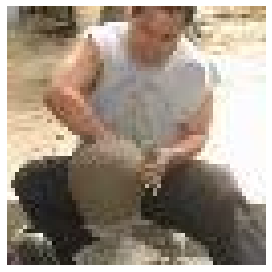

In [20]:
show_image(denorm(xi));

In [21]:
tdl = DataLoader(tfm_tds, batch_size=bs, shuffle=True, num_workers=8)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [22]:
xb,yb = b = next(iter(tdl))

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


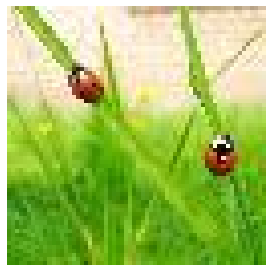

In [23]:
show_image(denorm(xb[0]));

In [24]:
all_synsets = [o.split('\t') for o in (path/'words.txt').read_text().splitlines()]

    how txt file look:
    n00006484	cell
    n00007347	causal agent, cause, causal agency
    n00007846	person, individual, someone, somebody, mortal, soul

In [25]:
all_synsets[5:8]

[['n00003553', 'whole, unit'],
 ['n00003993', 'congener'],
 ['n00004258', 'living thing, animate thing']]

In [26]:
synsets = {k:v.split(',', maxsplit=1)[0] for k,v in all_synsets if k in id2str}

take the first label, ignore others

In [27]:
synsets

{'n01443537': 'goldfish',
 'n01629819': 'European fire salamander',
 'n01641577': 'bullfrog',
 'n01644900': 'tailed frog',
 'n01698640': 'American alligator',
 'n01742172': 'boa constrictor',
 'n01768244': 'trilobite',
 'n01770393': 'scorpion',
 'n01774384': 'black widow',
 'n01774750': 'tarantula',
 'n01784675': 'centipede',
 'n01855672': 'goose',
 'n01882714': 'koala',
 'n01910747': 'jellyfish',
 'n01917289': 'brain coral',
 'n01944390': 'snail',
 'n01945685': 'slug',
 'n01950731': 'sea slug',
 'n01983481': 'American lobster',
 'n01984695': 'spiny lobster',
 'n02002724': 'black stork',
 'n02056570': 'king penguin',
 'n02058221': 'albatross',
 'n02074367': 'dugong',
 'n02085620': 'Chihuahua',
 'n02094433': 'Yorkshire terrier',
 'n02099601': 'golden retriever',
 'n02099712': 'Labrador retriever',
 'n02106662': 'German shepherd',
 'n02113799': 'standard poodle',
 'n02123045': 'tabby',
 'n02123394': 'Persian cat',
 'n02124075': 'Egyptian cat',
 'n02125311': 'cougar',
 'n02129165': 'lion'

In [28]:
titles = [synsets[id2str[o]] for o in yb]
', '.join(titles[:20])

'ladybug, espresso, birdhouse, fly, chain, sports car, African elephant, go-kart, Christmas stocking, beaker, goldfish, go-kart, sewing machine, school bus, scoreboard, swimming trunks, espresso, vestment, German shepherd, guacamole'

here is the labels in the batch

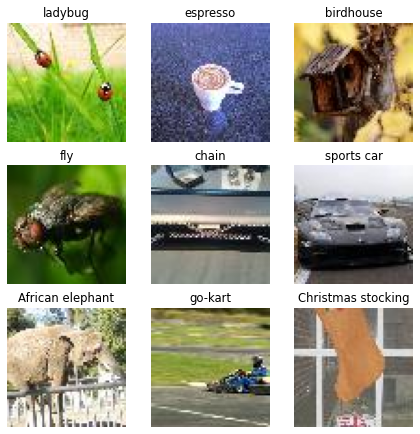

In [29]:
show_images(denorm(xb[:9]), titles=titles[:9], imsize=2.5)

In [30]:
dls = DataLoaders(*get_dls(tfm_tds, tfm_vds, bs=bs, num_workers=8))

    def get_dls(train_ds, valid_ds, bs, **kwargs):
        return (DataLoader(train_ds, batch_size=bs, shuffle=True, **kwargs),
                DataLoader(valid_ds, batch_size=bs*2, **kwargs))

# Basic Model

In [31]:
def tfm_batch(b,tfm_x=fc.noop, tfm_y=fc.noop): return  tfm_x(b[0]),tfm_y(b[1])

In [32]:
tfms = nn.Sequential(T.Pad(4), T.RandomCrop(64),
                     T.RandomHorizontalFlip(),
                     RandErase())
augcb = BatchTransformCB(partial(tfm_batch, tfm_x=tfms), on_val=False)

In [33]:
act_gr = partial(GeneralRelu,leak=0.1,sub=0.4)
iw = partial(init_weights, leaky=0.1)

In [34]:
nfs = (32,64,128,256,512,1024)

In [35]:
def get_dropmodel(act=act_gr, nfs=nfs, norm=nn.BatchNorm2d, drop=0.1):
    layers = [nn.Conv2d(3, nfs[0], 5, padding=2)]
#     layers += [ResBlock(nfs[0], nfs[0], ks=3, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2)
               for i in range(len(nfs)-1)]
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop)]
    layers += [nn.Linear(nfs[-1], 200, bias=False), nn.BatchNorm1d(200)]
    return nn.Sequential(*layers).apply(iw)

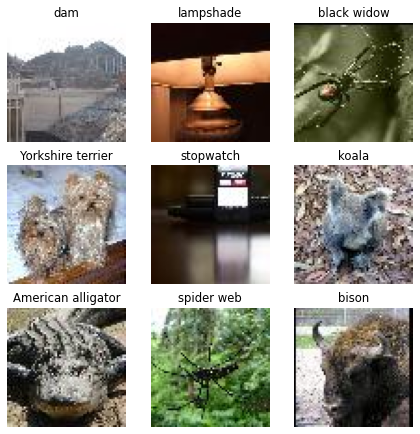

In [36]:
# Lets take a look at a batch
learn = TrainLearner(get_dropmodel(), dls, F.cross_entropy, cbs=[SingleBatchCB(), augcb, DeviceCB()])
learn.fit(1)
xb,yb = learn.batch
show_images(denorm(xb.cpu())[:9],titles=[synsets[id2str[o]] for o in yb][:9],imsize=2.5)

In [37]:
learn.summary()

Tot params: 19775824; MFLOPS: 303.7


|Module|Input|Output|Num params|MFLOPS|
|--|--|--|--|--|
|Conv2d|(512, 3, 64, 64)|(512, 32, 64, 64)|2432|9.8|
|ResBlock|(512, 32, 64, 64)|(512, 64, 32, 32)|57792|58.7|
|ResBlock|(512, 64, 32, 32)|(512, 128, 16, 16)|230272|58.7|
|ResBlock|(512, 128, 16, 16)|(512, 256, 8, 8)|919296|58.7|
|ResBlock|(512, 256, 8, 8)|(512, 512, 4, 4)|3673600|58.7|
|ResBlock|(512, 512, 4, 4)|(512, 1024, 2, 2)|14687232|58.7|
|AdaptiveAvgPool2d|(512, 1024, 2, 2)|(512, 1024, 1, 1)|0|0.0|
|Flatten|(512, 1024, 1, 1)|(512, 1024)|0|0.0|
|Dropout|(512, 1024)|(512, 1024)|0|0.0|
|Linear|(512, 1024)|(512, 200)|204800|0.2|
|BatchNorm1d|(512, 200)|(512, 200)|400|0.0|


    MFLOPS = params × H × W

    double channels → params ×4
    halve spatial   → H×W   ×0.25

    4 × 0.25 = 1 → MFLOPS stays the same every stage ✓

In [38]:
opt_func = partial(optim.AdamW, eps=1e-5)

In [39]:
lr_cbs = [DeviceCB(), augcb, MixedPrecision(), ProgressCB()]

/kaggle/working/course22p2/miniai/accel.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self, learn): self.scaler = torch.cuda.amp.GradScaler()


<div><div><progress max="10" value="0"></progress> 0.00% [0/10 00:00&lt;?]</div><div></div><div><progress max="196" value="41"></progress> 20.92% [41/196 00:13&lt;00:51... 5.019]</div></div>

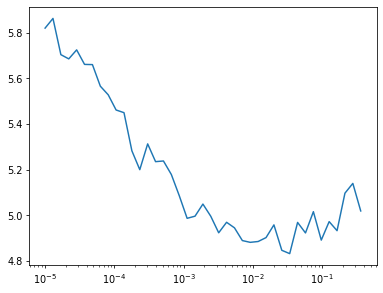

In [40]:
learn = Learner(get_dropmodel(), dls, F.cross_entropy, cbs=lr_cbs, opt_func=opt_func)
learn.lr_find()

In [41]:
class acc_100(MulticlassAccuracy):
    def compute(self): return super().compute()*100

In [42]:
metrics = MetricsCB(accuracy=acc_100())
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), MixedPrecision()]

In [43]:
epochs = 25
lr = 0.04
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched), augcb]
learn = Learner(get_dropmodel(), dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [44]:
# learn.fit(epochs)

In [45]:
# torch.save(learn.model,'../models/tiny_imagenet_base.pkl')

The gradient was near exploding here (huge jump) -> at the peak of the lr in the one cycle sched, but then it recovered -> 0.03 or 0.02 can be more stable

# Deeper

In [46]:
def res_blocks(n_bk, ni, nf, stride=2, ks=3, act=act_gr, norm=None):
    return nn.Sequential(*[
        ResBlock(ni if i==0 else nf, nf, act=act, norm=norm, stride=stride if i==n_bk-1 else 1 ) for i in range(n_bk)
    ])

- At beginning (1st ResNet) it transform features [`ni`->`nf`]
- At the end (last ResNet) it halves the `Spacial Dim`

In [47]:
n_bks = (3,2,2,1,1)

In [48]:
def get_dropmodel(act=act_gr, nfs=nfs, n_bks=n_bks, norm=nn.BatchNorm2d, drop=0.2):
    layers = [ResBlock(3,nfs[0],ks=5,stride=1,act=act,norm=norm)]
    layers += [res_blocks(n_bks[i],nfs[i],nfs[i+1],stride=2,act=act,norm=norm) for i in range(len(nfs)-1)]
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop)]
    layers += [nn.Linear(nfs[-1], 200, bias=False), nn.BatchNorm1d(200)]
    return nn.Sequential(*layers).apply(iw)

    at layer[0]:
    is it math or experiment? → experiment/convention
    plain Conv2d stem (original ResNet style) also works fine
    ResBlock stem = extra gradient path early, marginal benefit

    Why Making More ResNets?
    -> Deeper Model

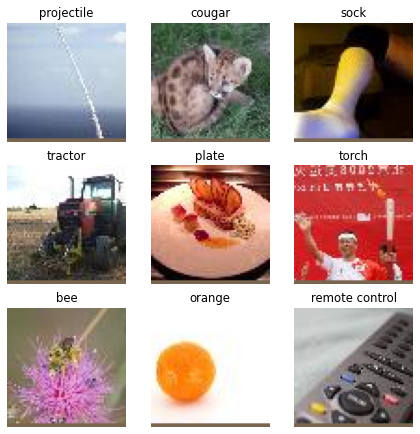

In [49]:
# see on batch
learn = TrainLearner(get_dropmodel(nfs=nfs), dls, F.cross_entropy, cbs=[SingleBatchCB(), augcb, DeviceCB()])
learn.fit(1)
xb,yb = learn.batch
show_images(denorm(xb.cpu())[:9],titles=[synsets[id2str[o]] for o in yb][:9], imsize=2.5)

In [50]:
learn.summary()

Tot params: 21426800; MFLOPS: 710.9


|Module|Input|Output|Num params|MFLOPS|
|--|--|--|--|--|
|ResBlock|(512, 3, 64, 64)|(512, 32, 64, 64)|28320|115.1|
|Sequential|(512, 32, 64, 64)|(512, 64, 32, 32)|206016|209.7|
|Sequential|(512, 64, 32, 32)|(512, 128, 16, 16)|525952|134.2|
|Sequential|(512, 128, 16, 16)|(512, 256, 8, 8)|2100480|134.2|
|Sequential|(512, 256, 8, 8)|(512, 512, 4, 4)|3673600|58.7|
|Sequential|(512, 512, 4, 4)|(512, 1024, 2, 2)|14687232|58.7|
|AdaptiveAvgPool2d|(512, 1024, 2, 2)|(512, 1024, 1, 1)|0|0.0|
|Flatten|(512, 1024, 1, 1)|(512, 1024)|0|0.0|
|Dropout|(512, 1024)|(512, 1024)|0|0.0|
|Linear|(512, 1024)|(512, 200)|204800|0.2|
|BatchNorm1d|(512, 200)|(512, 200)|400|0.0|


<div><div><progress max="10" value="0"></progress> 0.00% [0/10 00:00&lt;?]</div><div></div><div><progress max="196" value="42"></progress> 21.43% [42/196 00:40&lt;02:29... 5.036]</div></div>

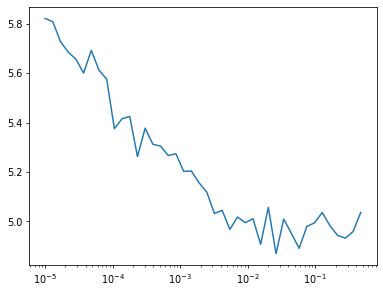

In [51]:
#lr finder
opt_func = partial(optim.AdamW, eps=1e-5)
learn = Learner(get_dropmodel(), dls, F.cross_entropy, cbs=lr_cbs, opt_func=opt_func)
learn.lr_find()

In [52]:
metrics = MetricsCB(accuracy=acc_100())
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), MixedPrecision()]

epochs = 25
lr = 3e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched), augcb]
learn = Learner(get_dropmodel(), dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [53]:
# learn.fit(epochs)

In [54]:
model_path = Path('models')
model_path.mkdir(exist_ok=True)

In [55]:
# torch.save(learn.model,model_path/'tiny_imagenet_deeper.pkl')

# More Augmentation
- To Help more with the overfitting

In [56]:
aug_tfms = nn.Sequential(T.Pad(4),
                         T.RandomCrop(64),
                         T.RandomHorizontalFlip(),
                         T.TrivialAugmentWide())
norm_tfms = T.Normalize(xmean,xstd)
erase_tfm = RandErase()

In [57]:
from PIL import Image

In [58]:
def tfmx(x, aug=False):
  x = Image.open(x).convert('RGB') #bec. not all images in ds is RGB
  if aug: x = aug_tfms(x)
  x = TF.to_tensor(x)
  x = norm_tfms(x)
  if aug : x = erase_tfm(x[None])[0]
  return x

why `Image.open` -> because some of the augmentations in `T.TrivialAugmentWide()` require `PIL`

And like that we are making the Augmentations inside the transforms, so now each image in the batch is going to have its own random augmentation, not all batch the same as before

In [59]:
tfm_tds = TfmDS(tds, tfmx=partial(tfmx,aug=True), tfmy=tfmy)
tfm_vds = TfmDS(vds, tfmx=tfmx, tfmy=tfmy)

In [71]:
dls = DataLoaders(*get_dls(tfm_tds, tfm_vds, bs=bs, num_workers=2)) # 2 num workers becuase training was on kaggle

In [61]:
# Make a conv where it make Norm->Activation->Conv
def conv(ni, nf, ks=3, stride=1, act=nn.ReLU, norm=None, bias=True):
    layers = []
    if norm: layers.append(norm(ni))
    if act : layers.append(act())
    layers.append(nn.Conv2d(ni, nf, stride=stride, kernel_size=ks, padding=ks//2, bias=bias))
    return nn.Sequential(*layers)
# Make conv_blcok with activation added in 2nd conv
def _conv_block(ni, nf, stride, act=act_gr, norm=None, ks=3):
    return nn.Sequential(conv(ni, nf, stride=1     , act=act, norm=norm, ks=ks),
                         conv(nf, nf, stride=stride, act=act, norm=norm, ks=ks))
# Make ResBlock Where There is no activation on the final output at forward
class ResBlock(nn.Module):
    def __init__(self, ni, nf, stride=1, ks=3, act=act_gr, norm=None):
        super().__init__()
        self.convs = _conv_block(ni, nf, stride, act=act, ks=ks, norm=norm)
        self.idconv = fc.noop if ni==nf else conv(ni, nf, ks=1, stride=1, act=None, norm=norm)
        self.pool = fc.noop if stride==1 else nn.AvgPool2d(2, ceil_mode=True)

    def forward(self, x): return self.convs(x) + self.idconv(self.pool(x))
# make a get_model
def get_dropmodel(act=act_gr, nfs=nfs, nbks=n_bks, norm=nn.BatchNorm2d, drop=0.2):
    layers = [nn.Conv2d(3, nfs[0], 5, padding=2)]
    layers += [res_blocks(nbks[i], nfs[i], nfs[i+1], act=act, norm=norm, stride=2)
               for i in range(len(nfs)-1)]
    layers += [act_gr(), norm(nfs[-1]), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop)]
    layers += [nn.Linear(nfs[-1], 200, bias=False), nn.BatchNorm1d(200)]
    return nn.Sequential(*layers).apply(iw)


- At `layers = [nn.Conv2d(3, nfs[0], 5, padding=2)]`-> cannot make it `ResBlock` because it have `activation` and `norm` at the beggining so it is going to kill lots of data features
- At `layers += [act_gr(), norm(nfs[-1]), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop)]`, we put `act` and `norm` because at new resnets it start with `act` and `norm` and end with convolution(weights), so we normalize and put activation on this convolution outputs

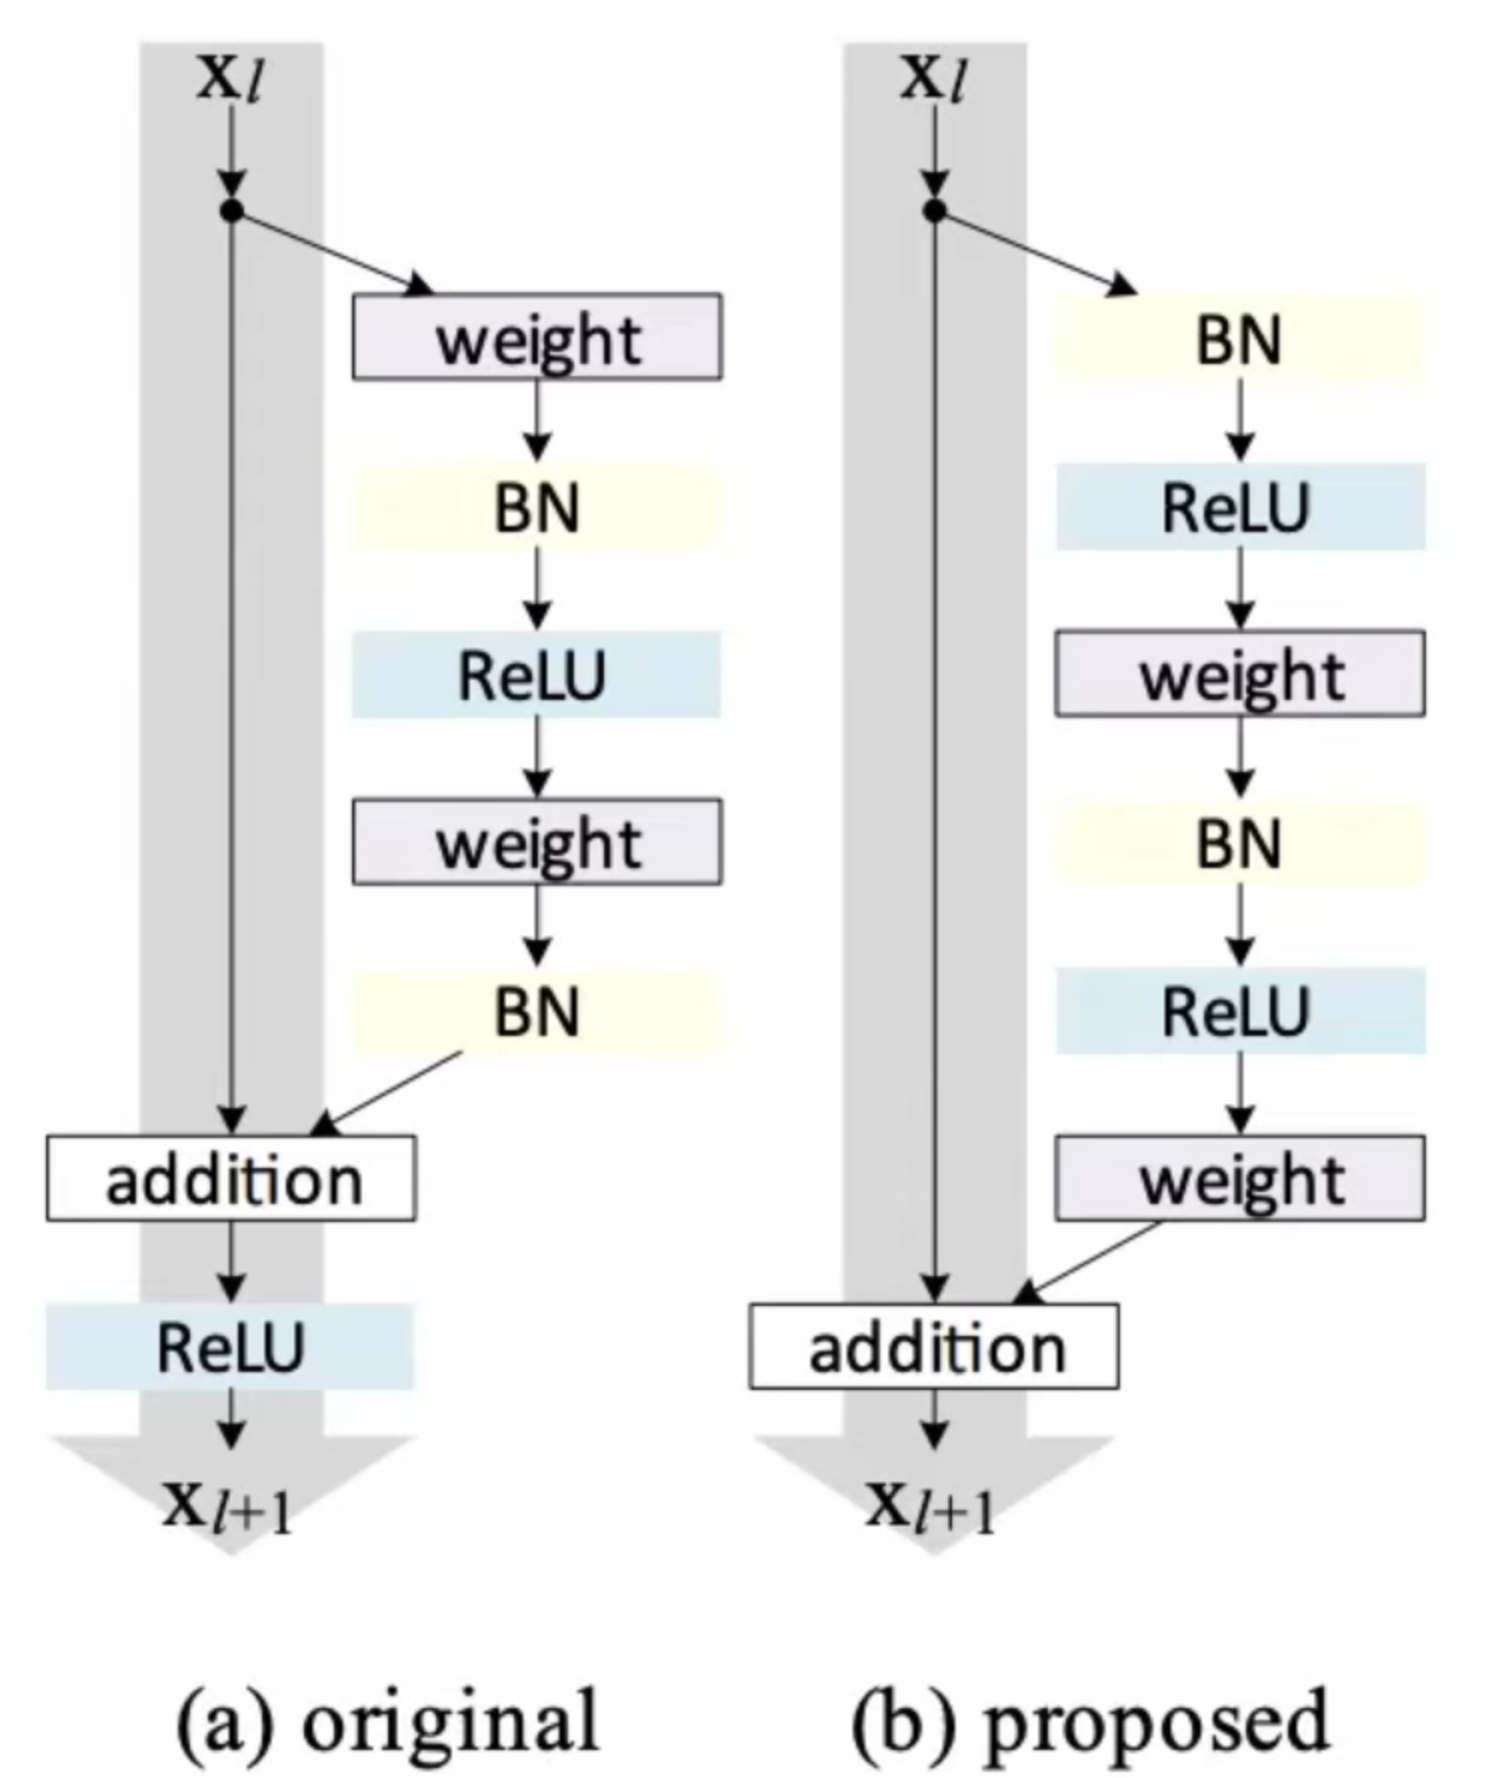

In [62]:
def get_model(): return nn.DataParallel(get_dropmodel(nbks=(4,3,3,2,1), drop=0.1))

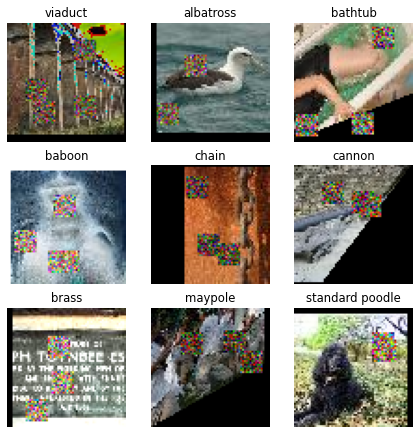

In [63]:
learn = TrainLearner(get_model(), dls, F.cross_entropy, cbs=[SingleBatchCB(), DeviceCB()])
learn.fit(1)
xb,yb = learn.batch
show_images(denorm(xb.cpu())[:9],titles=[synsets[id2str[o]] for o in yb][:9], imsize=2.5)

We can see each image have different augmentation

<div><div><progress max="10" value="0"></progress> 0.00% [0/10 00:00&lt;?]</div><div></div><div><progress max="196" value="55"></progress> 28.06% [55/196 00:36&lt;01:32... 7.482]</div></div>

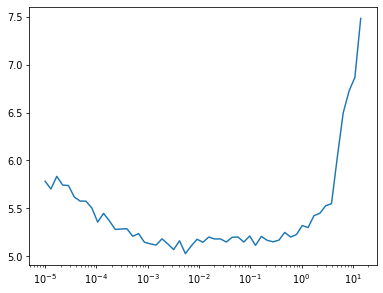

In [64]:
learn = Learner(get_model(), dls, F.cross_entropy, cbs=lr_cbs, opt_func=opt_func)
learn.lr_find()

In [69]:
epochs = 50
lr = 0.1
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(get_model(), dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

accuracy,loss,epoch,train
1.730,5.148,0,train
2.750,4.980,0,eval
3.319,4.926,1,train
4.900,4.751,1,eval
5.886,4.686,2,train
9.230,4.351,2,eval
8.648,4.431,3,train
11.550,4.162,3,eval
11.704,4.188,4,train
13.750,4.088,4,eval


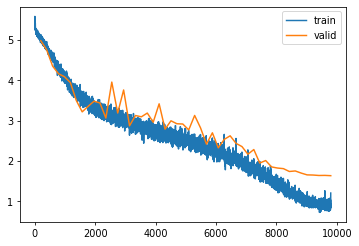

In [72]:
learn.fit(epochs)

    76.132	0.920	49	train
    62.820	1.638	49	eval
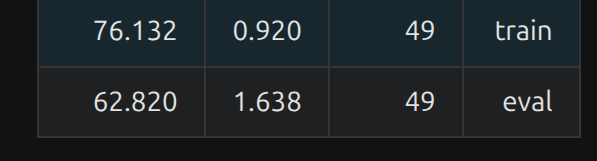

In [73]:
def get_model(): return nn.DataParallel(get_dropmodel(nbks=(4,3,3,2,1), drop=0.3)) # try a higher dropout
epochs = 50
lr = 0.1
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = Learner(get_model(), dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

accuracy,loss,epoch,train
2.135,5.081,0,train
3.140,4.991,0,eval
4.381,4.805,1,train
6.020,4.583,1,eval
7.308,4.532,2,train
9.020,4.366,2,eval
10.333,4.271,3,train
12.220,4.132,3,eval
13.477,4.031,4,train
11.920,4.377,4,eval


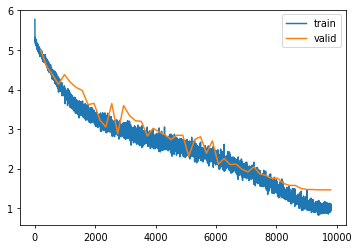

In [74]:
learn.fit(epochs)

In [75]:
torch.save(learn.model,model_path/'tiny_imagenet_deeper_Aug.pkl')

    73.935	1.000	49	train
    65.390	1.465	49	eval